[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmedelshazly27/mizan-kuwait-energy-toolkit/blob/main/notebooks/03-demand-reconstruction.ipynb)

In [1]:
# On Colab: clone the repository and install it (inputs are committed, no credentials needed).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mizan-kuwait-energy-toolkit"):
    !git clone --depth 1 https://github.com/ahmedelshazly27/mizan-kuwait-energy-toolkit.git
    %pip install -q -e "mizan-kuwait-energy-toolkit[pv,econ,system]" matplotlib
    os.chdir("mizan-kuwait-energy-toolkit")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from kwtk import viz; viz.style()

# 3. Hourly demand: a reconstruction

No hourly Kuwaiti load is published. The series in `inputs/demand/` is modelled from
monthly energy, annual peaks and population-weighted ERA5 temperature, fitted to
MEW's daily data, and checked against the four half-hourly curves the yearbooks print
for the yearly peak day, which the fit never sees (decisions D1-D3).

In [2]:
import json
from kwtk.inputs import demand
meta = json.load(open('inputs/demand/kuwait-gross-load-reconstructed.json'))
print(meta['label']); pd.DataFrame(meta['validation_peak_days']).round(3)

RECONSTRUCTION: hourly gross system load modelled from monthly energy, annual peaks and ERA5 temperature; not a measurement


,source_id,day,hours,mape,max_abs_error,printed_peak_hour,model_peak_hour,printed_min_hour,model_min_hour
0,mew-yb-2020,2020-07-30,25,0.049,0.128,15,14,6,7
1,mew-yb-2021,2021-07-28,25,0.038,0.097,15,15,6,7
2,mew-yb-2022,2022-08-09,25,0.038,0.107,14,15,6,7
3,mew-yb-2023,2023-08-02,25,0.040,0.102,14,15,6,7


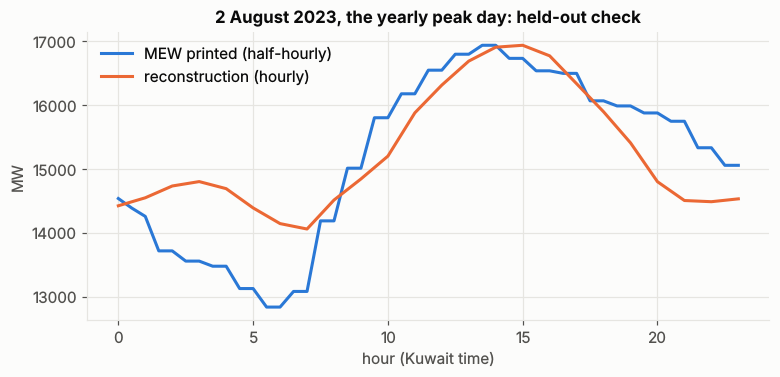

In [3]:
L = demand.load_series()
c = demand.peak_curves(); c = c[c.source_id == 'mew-yb-2023'].set_index('t').mw
c = c[c.index.normalize() == c.index[0].normalize()]      # the printed closing 0:00 belongs to the next day
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(c.index.hour + c.index.minute / 60, c.values, label='MEW printed (half-hourly)')
m = L['2023-08-02']; ax.plot(m.index.hour, m.values, label='reconstruction (hourly)')
ax.set_title('2 August 2023, the yearly peak day: held-out check'); ax.set_ylabel('MW'); ax.set_xlabel('hour (Kuwait time)')
ax.legend(); plt.show()

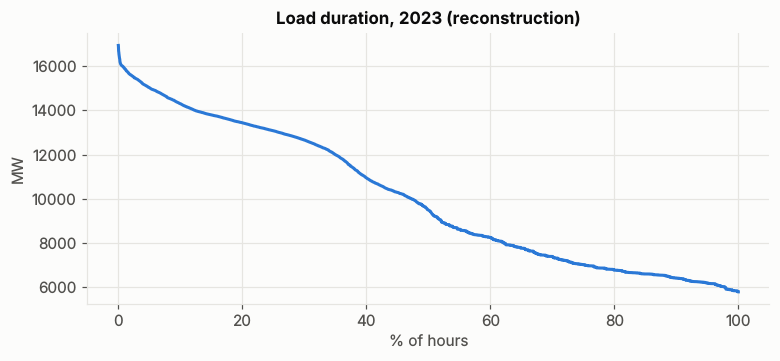

In [4]:
y = L['2023']
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.arange(len(y)) / len(y) * 100, np.sort(y.values)[::-1])
ax.set_title('Load duration, 2023 (reconstruction)'); ax.set_ylabel('MW'); ax.set_xlabel('% of hours')
plt.show()

Known defects (night too high, a large peak stretch, a non-summer shape that is an assumption) are listed in `docs/demand-reconstruction.md`.